In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
print(os.listdir("data"))

['Online Retail.xlsx']


In [2]:
df = pd.read_excel("data/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print(df.shape)
df.info()

(541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [6]:
df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [7]:
df_clean = df.copy()
print("start:", len(df_clean))

# 1. Drop rows with no customer ID
df_clean = df_clean.dropna(subset=["CustomerID"])
print("after dropping rows with no customer ID:", len(df_clean))

# 2. Remove cancelled invoices (invoiceNo starting with "C")
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)
df_clean = df_clean[~df_clean["InvoiceNo"].str.startswith("C")]
print("After removing cancellations:", len(df_clean))


start: 541909
after dropping rows with no customer ID: 406829
After removing cancellations: 397924


In [8]:
# 3. Keep only real sales: positive quantity AND positive price
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["UnitPrice"] > 0)]
print("After removing bad quantity/price:", len(df_clean))

After removing bad quantity/price: 397884


In [9]:
# 4. Remove exact duplicate rows
print("Duplicates found:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print("After removing duplicates:", len(df_clean))

Duplicates found: 5192
After removing duplicates: 392692


In [10]:
# CustomerID: float -> whole number -> text label
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int).astype(str)

# New column: money for each row
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]

In [11]:
print("Shape:", df_clean.shape)
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Date range:", df_clean["InvoiceDate"].min(), "to", df_clean["InvoiceDate"].max())
print(df_clean[["Quantity", "UnitPrice", "TotalPrice"]].describe())

Shape: (392692, 9)
Unique customers: 4338
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
            Quantity      UnitPrice     TotalPrice
count  392692.000000  392692.000000  392692.000000
mean       13.119702       3.125914      22.631500
std       180.492832      22.241836     311.099224
min         1.000000       0.001000       0.001000
25%         2.000000       1.250000       4.950000
50%         6.000000       1.950000      12.450000
75%        12.000000       3.750000      19.800000
max     80995.000000    8142.750000  168469.600000


In [12]:
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)
print(snapshot_date)

2011-12-10 12:50:00


In [13]:
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

print(rfm.shape)
rfm.head()

(4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [14]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [15]:
rfm.sort_values("Monetary", ascending=False).head(5)

,CustomerID,Recency,Frequency,Monetary
1689,14646,2,73,280206.02
4201,18102,1,60,259657.30
3728,17450,8,46,194390.79
3008,16446,1,2,168472.50
1879,14911,1,201,143711.17


In [16]:
check = df[df["CustomerID"].isin([12346.0, 16446.0])]
check.sort_values(["CustomerID", "InvoiceDate"])[["CustomerID", "InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]]

,CustomerID,InvoiceNo,InvoiceDate,Quantity,UnitPrice
61619,12346.0,541431,2011-01-18 10:01:00,74215,1.04
61624,12346.0,C541433,2011-01-18 10:17:00,-74215,1.04
194354,16446.0,553573,2011-05-18 09:52:00,1,1.65
194355,16446.0,553573,2011-05-18 09:52:00,1,1.25
540421,16446.0,581483,2011-12-09 09:15:00,80995,2.08
540422,16446.0,C581484,2011-12-09 09:27:00,-80995,2.08


In [17]:
rfm = rfm[~rfm["CustomerID"].isin(["12346", "16446"])].reset_index(drop=True)
print(rfm.shape)

(4336, 4)


In [18]:
print(rfm.sort_values("Monetary", ascending=False).head(5))
rfm.describe()

     CustomerID  Recency  Frequency   Monetary
1688      14646        2         73  280206.02
4199      18102        1         60  259657.30
3726      17450        8         46  194390.79
1878      14911        1        201  143711.17
54        12415       24         21  124914.53


,Recency,Frequency,Monetary
count,4336.000000,4336.000000,4336.000000
mean,92.503690,4.273293,1992.978043
std,99.964702,7.699536,8548.515874
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.457500
50%,51.000000,2.000000,668.495000
75%,142.000000,5.000000,1657.897500
max,374.000000,209.000000,280206.020000


In [19]:
rfm["R_Score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1])
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5])

# qcut returns a category type, so convert to whole numbers
for col in ["R_Score", "F_Score", "M_Score"]:
    rfm[col] = rfm[col].astype(int)

In [20]:
rfm["RFM_Segment"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)
rfm["RFM_Total"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment,RFM_Total
0,12347,2,7,4310.00,5,5,5,555,15
1,12348,75,4,1797.24,2,4,4,244,10
2,12349,19,1,1757.55,4,1,4,414,9
3,12350,310,1,334.40,1,1,2,112,4
4,12352,36,8,2506.04,3,5,5,355,13
5,12353,204,1,89.00,1,1,1,111,3
6,12354,232,1,1079.40,1,1,4,114,6
7,12355,214,1,459.40,1,1,2,112,4
8,12356,23,3,2811.43,4,3,5,435,12
9,12357,33,1,6207.67,4,1,5,415,10


In [21]:
print(rfm.groupby("R_Score")["Recency"].agg(["min", "max", "count"]))
print(rfm.groupby("F_Score")["Frequency"].agg(["min", "max", "count"]))
print(rfm.groupby("M_Score")["Monetary"].agg(["min", "max", "count"]))

         min  max  count
R_Score                 
1        180  374    864
2         73  179    843
3         34   72    858
4         15   33    888
5          1   14    883
         min  max  count
F_Score                 
1          1    1    868
2          1    2    867
3          2    3    867
4          3    6    867
5          6  209    867
             min        max  count
M_Score                           
1           3.75     249.00    868
2         249.86     487.02    867
3         487.51     932.97    867
4         933.26    2053.02    867
5        2054.36  280206.02    867


In [22]:
print(rfm.sort_values("RFM_Total", ascending=False).head(5))
print(rfm.sort_values("RFM_Total").head(5))

     CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0         12347        2          7   4310.00        5        5        5   
3062      16523        2         21   9418.47        5        5        5   
661       13225        3          7   6463.84        5        5        5   
666       13230        4         14   2755.63        5        5        5   
3107      16592        4         16   4113.68        5        5        5   

     RFM_Segment  RFM_Total  
0            555         15  
3062         555         15  
661          555         15  
666          555         15  
3107         555         15  
     CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
2477      15717      234          1    150.30        1        1        1   
173       12565      289          1    145.92        1        1        1   
2268      15437      262          1    200.16        1        1        1   
912       13570      243          1    239.49        1     

In [23]:
import numpy as np

conditions = [
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 4),
    (rfm["R_Score"] >= 4) & (rfm["F_Score"].isin([2, 3])),
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] == 1),
    (rfm["R_Score"] == 3) & (rfm["F_Score"] >= 3),
    (rfm["R_Score"] == 3) & (rfm["F_Score"] <= 2),
    (rfm["R_Score"] <= 2) & (rfm["F_Score"] >= 3),
    (rfm["R_Score"] == 1) & (rfm["F_Score"] == 1),
]
labels = ["Champions", "Potential Loyalists", "New Customers", "Loyal Customers",
          "Need Attention", "At Risk", "Lost"]

rfm["Segment"] = np.select(conditions, labels, default="Hibernating")

In [24]:
seg_counts = rfm["Segment"].value_counts()
print(seg_counts)
print((seg_counts / len(rfm) * 100).round(1))

Segment
Champions              1139
Hibernating             701
At Risk                 643
Loyal Customers         507
Potential Loyalists     490
Lost                    363
Need Attention          351
New Customers           142
Name: count, dtype: int64
Segment
Champions              26.3
Hibernating            16.2
At Risk                14.8
Loyal Customers        11.7
Potential Loyalists    11.3
Lost                    8.4
Need Attention          8.1
New Customers           3.3
Name: count, dtype: float64


In [25]:
profile = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(1)

profile["Revenue_Share_%"] = (profile["Total_Revenue"] / profile["Total_Revenue"].sum() * 100).round(1)
profile.sort_values("Total_Revenue", ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Revenue_Share_%
Segment,,,,,,
Champions,1139,13.3,10.0,5191.8,5913422.1,68.4
Loyal Customers,507,51.5,4.5,1850.8,938338.8,10.9
At Risk,643,152.8,3.4,1241.1,798052.5,9.2
Potential Loyalists,490,17.1,2.0,690.1,338135.9,3.9
Hibernating,701,186.3,1.2,457.2,320516.3,3.7
Need Attention,351,53.5,1.2,459.0,161108.1,1.9
Lost,363,278.6,1.0,332.3,120622.3,1.4
New Customers,142,18.5,1.0,361.7,51356.9,0.6


In [26]:
print(rfm["Segment"].isnull().sum(), len(rfm), seg_counts.sum())

0 4336 4336


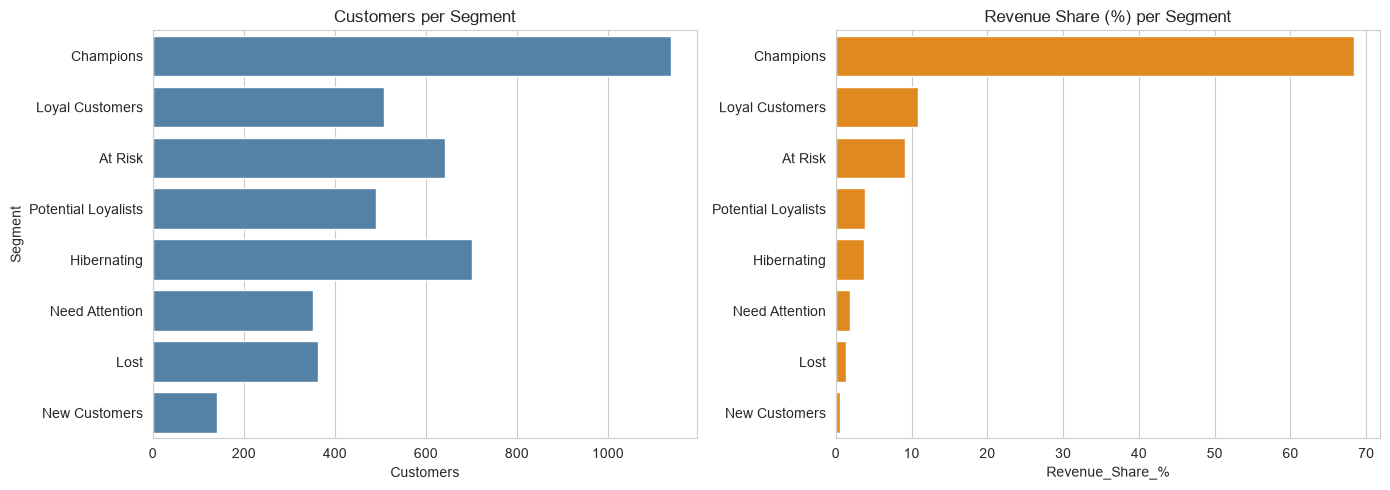

In [29]:
order = profile.sort_values("Total_Revenue", ascending=False).index
plot_df = profile.loc[order].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=plot_df, y="Segment", x="Customers", ax=axes[0], color="steelblue")
axes[0].set_title("Customers per Segment")

sns.barplot(data=plot_df, y="Segment", x="Revenue_Share_%", ax=axes[1], color="darkorange")
axes[1].set_title("Revenue Share (%) per Segment")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("images/segment_size_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
import os
os.makedirs("images", exist_ok=True)

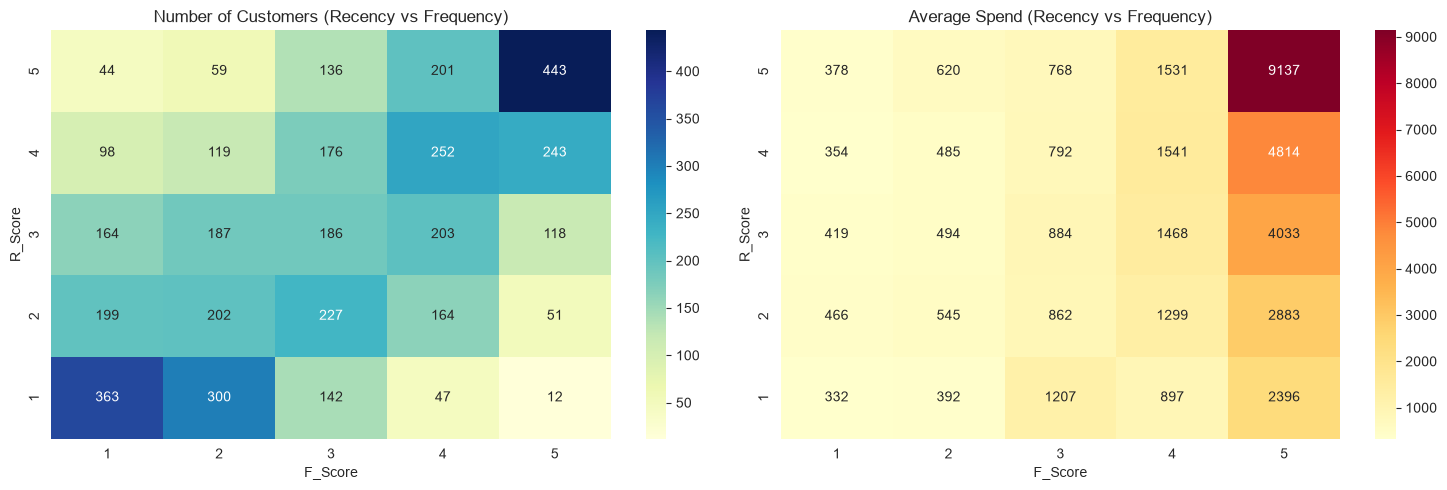

In [30]:
count_pivot = rfm.pivot_table(index="R_Score", columns="F_Score", values="CustomerID", aggfunc="count")
money_pivot = rfm.pivot_table(index="R_Score", columns="F_Score", values="Monetary", aggfunc="mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(count_pivot.sort_index(ascending=False), annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Number of Customers (Recency vs Frequency)")

sns.heatmap(money_pivot.sort_index(ascending=False), annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[1])
axes[1].set_title("Average Spend (Recency vs Frequency)")

plt.tight_layout()
plt.savefig("images/rfm_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
rfm.to_csv("rfm_segments.csv", index=False)

## Marketing recommendations

| Segment | Size / revenue | Idea |
|---|---|---|
| Champions | 26% of customers, 68% of revenue | Reward them: early access to new products, a loyalty tier, thank-you notes. Do not give deep discounts, they already buy. |
| Loyal Customers | 12%, 11% of revenue | Upsell and cross-sell, offer bundles, invite them to a loyalty program. |
| Potential Loyalists | 11%, 4% | Encourage a third order: small "next purchase" coupon, product recommendations. |
| New Customers | 3%, 1% | Welcome email series, a small discount on the second order. |
| Need Attention | 8%, 2% | Time-limited offers and reminders before they drift away. |
| At Risk | 15%, 9% | Highest priority win-back: personal "we miss you" message plus a stronger discount. |
| Hibernating | 16%, 4% | Low-cost automated re-engagement email, then stop if no response. |
| Lost | 8%, 1% | Minimal effort: one last survey or offer, then remove from active campaigns. |